In [16]:
import tensorflow as tf

In [31]:
import pandas as pd
import numpy as np
# import pandas_datareader.data as web
from arch import arch_model
from scipy.optimize import minimize
import yfinance as yf
from scipy.stats import norm
import matplotlib.pyplot as plt

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
import duckdb
import pandas as pd

# Connect to your existing DuckDB database
conn = duckdb.connect('/Users/irikadesai/Desktop/stock_option (1).duckdb')

In [11]:
# Load NVDA stock data
# Load stock data
prices = conn.execute("""
    SELECT *
    FROM NVDA_stock
    ORDER BY timestamp
""").df()

# Load options data
options = conn.execute("""
    SELECT *
    FROM NVDA_option
    ORDER BY datetime
""").df()


# Convert timestamps
prices["timestamp"] = pd.to_datetime(prices["timestamp"])
options["datetime"] = pd.to_datetime(options["datetime"])
options["expiration"] = pd.to_datetime(options["expiration"])

# Convert stock prices to numeric
prices["mid_close"] = pd.to_numeric(
    prices["mid_close"], errors="coerce"
)

# Remove missing stock prices
prices = prices.dropna(subset=["mid_close"])

# Create daily stock prices
prices["date"] = prices["timestamp"].dt.normalize()

daily_prices = (
    prices.groupby("date")["mid_close"]
    .last()
    .to_frame()
)

daily_prices.index = pd.to_datetime(daily_prices.index)

# Calculate log returns
log_returns = np.log(
    daily_prices["mid_close"]
).diff().dropna()

# Calculate percentage returns
returns = daily_prices["mid_close"].pct_change().dropna()

print(daily_prices.head())
print(options.head())

            mid_close
date                 
2006-09-06       0.45
2006-09-07       0.46
2006-09-08       0.46
2006-09-11       0.47
2006-09-12       0.48
  underlying expiration option_type  strike            datetime   open   high  \
0       NVDA 2024-08-23        call    83.0 2024-08-23 09:30:00  42.70  42.85   
1       NVDA 2024-08-23        call    94.0 2024-08-23 09:30:00  31.64  31.64   
2       NVDA 2024-08-23        call    95.0 2024-08-23 09:30:00  30.66  30.66   
3       NVDA 2024-08-23        call   100.0 2024-08-23 09:30:00  25.70  25.70   
4       NVDA 2024-08-23        call   104.0 2024-08-23 09:30:00  21.70  21.70   

     low  close  volume  transactions  
0  42.70  42.70       7             3  
1  31.64  31.64       1             1  
2  30.65  30.65       6             2  
3  25.70  25.70      17             1  
4  21.70  21.70       2             1  


In [13]:
# Historical volatility (20-day)
historical_vol = np.sqrt(
    returns.pow(2).rolling(20).sum()
) * np.sqrt(252 / 20)

# Parameters
RISK_FREE_RATE = 0.04
DIVIDEND_YIELD = 0.0
TRADING_DAYS = 252

print("Stock observations:", len(daily_prices))
print("Option observations:", len(options))

print("Stock date range:",
      daily_prices.index.min(),
      daily_prices.index.max())

print("Option date range:",
      options["datetime"].min(),
      options["datetime"].max())

Stock observations: 5027
Option observations: 39845928
Stock date range: 2006-09-06 00:00:00 2026-08-31 00:00:00
Option date range: 2024-08-23 09:30:00 2026-08-31 16:00:00


In [14]:
# --------------------------------------------------
# OPTION DATA PREPARATION
# --------------------------------------------------

options["quote_date"] = (
    options["datetime"].dt.normalize()
)

options["option_type"] = (
    options["option_type"].str.lower().str.strip()
)

for col in ["strike", "open", "high", "low", "close"]:
    options[col] = pd.to_numeric(
        options[col], errors="coerce"
    )

options = options.dropna(
    subset=[
        "quote_date",
        "expiration",
        "strike",
        "close",
        "option_type"
    ]
)

# Actual observed option price
options["market_price"] = options["close"]

# Keep final available observation for each contract per day
options = (
    options.sort_values("datetime")
    .groupby(
        [
            "quote_date",
            "expiration",
            "option_type",
            "strike"
        ],
        as_index=False
    )
    .tail(1)
    .copy()
)

# Convert expiration dates to market closing time.
# Your expiration field only contains a date.
options["expiration_datetime"] = (
    options["expiration"].dt.normalize()
    + pd.Timedelta(hours=16)
)

# Actual time to expiration
options["T"] = (
    options["expiration_datetime"] - options["datetime"]
).dt.total_seconds() / (365 * 24 * 60 * 60)

# Remove expired contracts and invalid prices
options = options[
    (options["T"] > 0) &
    (options["market_price"] > 0) &
    (options["strike"] > 0)
].copy()

print(options.head())

    underlying expiration option_type  strike            datetime   open  \
430       NVDA 2024-08-23         put    31.0 2024-08-23 09:30:00   0.01   
431       NVDA 2024-08-23         put    34.0 2024-08-23 09:30:00   0.01   
432       NVDA 2024-08-23         put    83.0 2024-08-23 09:30:00   0.01   
476       NVDA 2024-09-06         put   200.0 2024-08-23 09:30:00  74.90   
79        NVDA 2024-09-20        call   213.0 2024-08-23 09:30:00   0.21   

      high    low  close  volume  transactions           timestamp  \
430   0.01   0.01   0.01       6             2 2024-08-23 09:30:00   
431   0.01   0.01   0.01       1             1 2024-08-23 09:30:00   
432   0.01   0.01   0.01      70             1 2024-08-23 09:30:00   
476  74.90  74.90  74.90       1             1 2024-08-23 09:30:00   
79    0.21   0.21   0.21       3             1 2024-08-23 09:30:00   

     underlying_price quote_date  market_price expiration_datetime         T  
430             125.6 2024-08-23          0

APARCH Model

In [15]:
def fit_team_aparch_t(returns_series: pd.Series, forecast_horizon: int = 1) -> dict:
    """
    Fits an APARCH(1,1) model with Student's t-errors to a % scaled return series.
    """
    # Fit APARCH(1,1) with Student's t-distribution
    model = arch_model(
        returns_series,
        mean='Constant',
        vol='APARCH',
        p=1, o=1, q=1,
        dist='StudentsT'  # Captures heavy tails via estimated degrees of freedom (nu)
    )
    
    results = model.fit(disp='off')
    
    # Structure parameters alongside p-values for diagnostic checks
    fitted_parameters = {
        param: {
            "val": float(results.params[param]),
            "pvalue": float(results.pvalues[param])
        }
        for param in results.params.index
    }
    
    # --- Calculate In-Sample QLIKE Loss ---
    # In 'arch', resid gives epsilon_t, and conditional_volatility gives sigma_t
    y_true = results.resid ** 2
    y_pred = results.conditional_volatility ** 2
    
    # Calculate element-wise QLIKE and take the mean
    ratio = y_true / y_pred
    qlike_loss = np.mean(ratio - np.log(ratio) - 1)
    
    # Out-of-sample volatility forecast
    forecast_obj = results.forecast(horizon=forecast_horizon)
    raw_variance_forecast = forecast_obj.variance.iloc[-1].values
    volatility_forecast = np.sqrt(raw_variance_forecast)
    
    last_date = returns_series.index[-1]
    future_dates = pd.date_range(start=last_date, periods=forecast_horizon + 1, freq='B')[1:]
    
    labeled_volatility_forecast = {
        date.strftime('%Y-%m-%d'): float(vol) 
        for date, vol in zip(future_dates, volatility_forecast)
    }
    
    return {
        "parameters": fitted_parameters,
        "log_likelihood": results.loglikelihood,
        "aic": results.aic,
        "bic": results.bic,
        "qlike": qlike_loss,  # <-- Added to return dict
        "forecasted_volatility": labeled_volatility_forecast
    }

if __name__ == "__main__":
    # 2. Fit Student's t APARCH
    output = fit_team_aparch_t(log_returns, forecast_horizon=1)

    print("--- Model Performance (Student's t APARCH) ---")
    print(f"Log-Likelihood: {output['log_likelihood']:.4f}")
    print(f"AIC:            {output['aic']:.4f}")
    print(f"BIC:            {output['bic']:.4f}")
    print(f"QLIKE Loss:     {output['qlike']:.6f}\n")  # <-- New metric output

    print("--- Fitted Parameters & Significance ---")
    print(f"{'Parameter':<10} | {'Value':<10} | {'p-value':<10} | {'Status'}")
    print("-" * 48)
    for param, metrics in output['parameters'].items():
        sig = "Significant" if metrics['pvalue'] < 0.05 else "Not Significant"
        print(f"{param:<10} | {metrics['val']:<10.6f} | {metrics['pvalue']:<10.4e} | {sig}")
        
    print("\n--- Dated 1-Day Volatility Forecast ---")
    for date, vol in output['forecasted_volatility'].items():
        print(f"{date}: {vol:.6f}% daily std dev")



/Users/irikadesai/Desktop/Python Folder/.venv/lib/python3.9/site-packages/arch/univariate/base.py:309: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.001038. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(


--- Model Performance (Student's t APARCH) ---
Log-Likelihood: 5999.0209
AIC:            -11984.0419
BIC:            -11938.3852
QLIKE Loss:     3.603972

--- Fitted Parameters & Significance ---
Parameter  | Value      | p-value    | Status
------------------------------------------------
mu         | 0.002028   | 7.2221e-07 | Significant
omega      | 0.061655   | 0.0000e+00 | Significant
alpha[1]   | 0.074924   | 1.4597e-04 | Significant
gamma[1]   | -0.172919  | 1.4633e-02 | Significant
beta[1]    | 0.348948   | 0.0000e+00 | Significant
delta      | 1.092525   | 0.0000e+00 | Significant
nu         | 66.459832  | 0.0000e+00 | Significant

--- Dated 1-Day Volatility Forecast ---
2026-09-01: 0.117229% daily std dev


In [22]:
# --------------------------------------------------
# APARCH-GARCH FORECASTS
# --------------------------------------------------

def forecast_garch_volatility(
    returns_series,
    forecast_dates,
    max_observations=1500
):

    forecasts = {}

    for date in sorted(pd.to_datetime(forecast_dates).unique()):

        date = pd.Timestamp(date)

        # Only information available before option date
        historical_returns = (
            returns_series.loc[returns_series.index < date]
            .dropna()
            .tail(max_observations)
        )

        if len(historical_returns) < 250:
            continue

        # Percentage returns for ARCH model
        scaled_returns = historical_returns * 100

        model = arch_model(
            scaled_returns,
            mean="Constant",
            vol="APARCH",
            p=1,
            o=1,
            q=1,
            dist="StudentsT"
        )

        try:

            fitted_model = model.fit(
                disp="off",
                show_warning=False
            )

            forecast = fitted_model.forecast(
                horizon=1,
                reindex=False
            )

            # One-day forecast variance
            variance = forecast.variance.iloc[-1, 0]

            # Daily decimal volatility
            daily_vol = np.sqrt(variance) / 100

            # Annualise
            annual_vol = daily_vol * np.sqrt(252)

            forecasts[date] = annual_vol

        except Exception as e:

            print(f"GARCH error on {date}: {e}")

    return pd.Series(
        forecasts,
        name="garch_vol"
    ).sort_index()


# Generate forecasts
garch_forecasts = forecast_garch_volatility(
    log_returns,
    options["quote_date"].unique()
)

print("GARCH forecasts:")
print(garch_forecasts.head())

GARCH forecasts:
2024-08-23    0.607587
2024-08-26    0.596021
2024-08-27    0.603430
2024-08-28    0.554773
2024-08-29    0.705512
Name: garch_vol, dtype: float64


LSTM Model

In [20]:
# --------------------------------------------------
# OPTIMIZED LSTM VOLATILITY MODEL
# --------------------------------------------------

# Use your existing Optuna parameters
# If best_params already exists, this uses it.

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

best_lookback = 10
best_hidden = 32
best_layers = 1
best_dropout = 0.2885
best_lr = 0.000939
best_batch = 32
best_epochs = 35

# Calculate 20-day realised volatility
volatility = np.sqrt(
    returns.pow(2).rolling(window=20).sum()
)

# Predict the next trading day's 20-day volatility
target = volatility.shift(-1).dropna()

# Remove missing observations from initial rolling window
target = target.dropna()

# Chronological split
data = target.to_numpy().reshape(-1, 1)

split_train = int(len(data) * 0.70)
split_val = int(len(data) * 0.85)

train_data = data[:split_train]
val_data = data[split_train:split_val]
test_data = data[split_val:]

# Fit scaler on training data only
scaler = StandardScaler()

train_scaled = scaler.fit_transform(train_data)
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

# Combine for sequence construction
all_scaled = np.vstack([
    train_scaled,
    val_scaled,
    test_scaled
])

def create_sequences(series, lookback):

    X, y, indices = [], [], []

    for i in range(lookback, len(series)):

        X.append(series[i-lookback:i])
        y.append(series[i, 0])
        indices.append(i)

    return (
        np.array(X),
        np.array(y),
        np.array(indices)
    )


# Create sequences
X_all, y_all, indices = create_sequences(
    all_scaled,
    best_lookback
)

# Training and validation masks
train_mask = indices < split_train

val_mask = (
    (indices >= split_train) &
    (indices < split_val)
)

test_mask = indices >= split_val

X_train = X_all[train_mask]
y_train = y_all[train_mask]

X_val = X_all[val_mask]
y_val = y_all[val_mask]

X_test = X_all[test_mask]
y_test = y_all[test_mask]

# Combine training and validation
train_val_scaled = np.vstack([
    train_scaled,
    val_scaled
])

X_train_val, y_train_val, _ = create_sequences(
    train_val_scaled,
    best_lookback
)

# Build optimized model
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

best_model = Sequential()

best_model.add(
    Input(shape=(best_lookback, 1))
)

for layer in range(best_layers):

    best_model.add(
        LSTM(
            units=best_hidden,
            return_sequences=(layer < best_layers - 1)
        )
    )

    best_model.add(
        Dropout(best_dropout)
    )

best_model.add(Dense(1))

best_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=best_lr
    ),
    loss="mae"
)

# Train on training and validation data
best_model.fit(
    X_train_val,
    y_train_val,
    epochs=best_epochs,
    batch_size=best_batch,
    shuffle=False,
    verbose=1
)

# Generate test predictions
predictions_scaled = best_model.predict(
    X_test,
    verbose=0
)

# Convert back to volatility units
predictions = scaler.inverse_transform(
    predictions_scaled
).flatten()

actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

# Ensure positive predictions
predictions = np.maximum(predictions, 1e-10)

# LSTM test evaluation
lstm_test_mae = mean_absolute_error(
    actual, predictions
)

print("Optimized LSTM Test MAE:", lstm_test_mae)

2026-11-12 21:08:07.343362: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2026-11-12 21:08:07.347383: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-11-12 21:08:07.348765: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-11-12 21:08:07.349927: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-12 21:08:07.351035: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Epoch 1/35


2026-11-12 21:08:08.364272: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


133/133 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.6910
Epoch 2/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.2859
Epoch 3/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.2163
Epoch 4/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.1989
Epoch 5/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1875
Epoch 6/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1743
Epoch 7/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1651
Epoch 8/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1573
Epoch 9/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1558
Epoch 10/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.1497
Epoch 11/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1485
Epoch 12/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.1495
Epoch 13/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.1432
Epoch 14/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.1437
Epoch 15/35
133/133 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step 

In [23]:
# --------------------------------------------------
# MAP LSTM FORECASTS TO DATES
# --------------------------------------------------

# Each target observation is indexed by its forecast origin.
# It predicts volatility for the next trading day.

test_indices = indices[test_mask]

lstm_forecast_dates = target.index[test_indices]

lstm_forecasts = pd.DataFrame({
    "forecast_origin": lstm_forecast_dates,
    "lstm_20day_vol": predictions
})

# The prediction is for the next trading day
trading_dates = daily_prices.index

next_trading_date = {
    trading_dates[i]: trading_dates[i + 1]
    for i in range(len(trading_dates) - 1)
}

lstm_forecasts["quote_date"] = (
    lstm_forecasts["forecast_origin"]
    .map(next_trading_date)
)

lstm_forecasts = lstm_forecasts.dropna(
    subset=["quote_date"]
)

# Convert 20-day realised volatility to annualised volatility
lstm_forecasts["lstm_vol"] = (
    lstm_forecasts["lstm_20day_vol"]
    * np.sqrt(252 / 20)
)

lstm_forecasts = (
    lstm_forecasts
    .set_index("quote_date")
    .sort_index()
)

print(lstm_forecasts.head())

           forecast_origin  lstm_20day_vol  lstm_vol
quote_date                                          
2023-08-31      2023-08-30        0.195547  0.694123
2023-09-01      2023-08-31        0.195125  0.692624
2023-09-05      2023-09-01        0.195754  0.694856
2023-09-06      2023-09-05        0.194831  0.691581
2023-09-07      2023-09-06        0.196415  0.697203


In [24]:
# --------------------------------------------------
# MATCH STOCK PRICES AND VOLATILITY FORECASTS
# --------------------------------------------------

# Match underlying stock price to each option observation
stock_intraday = (
    prices[["timestamp", "mid_close"]]
    .dropna()
    .sort_values("timestamp")
)

options = options.sort_values("datetime")

options = pd.merge_asof(
    options,
    stock_intraday,
    left_on="datetime",
    right_on="timestamp",
    direction="backward",
    tolerance=pd.Timedelta("5min")
)

options = options.rename(
    columns={"mid_close": "underlying_price"}
)

options = options.dropna(
    subset=["underlying_price"]
)

# Attach GARCH forecasts
options["garch_vol"] = (
    options["quote_date"].map(garch_forecasts)
)

# Attach LSTM forecasts
options["lstm_vol"] = (
    options["quote_date"].map(
        lstm_forecasts["lstm_vol"]
    )
)

# Historical volatility from the previous trading day
previous_date = {
    trading_dates[i]: trading_dates[i - 1]
    for i in range(1, len(trading_dates))
}

options["previous_trading_date"] = (
    options["quote_date"].map(previous_date)
)

options["historical_vol"] = (
    options["previous_trading_date"].map(historical_vol)
)

# Keep only observations with all three volatility estimates
options = options.dropna(
    subset=[
        "historical_vol",
        "garch_vol",
        "lstm_vol",
        "underlying_price"
    ]
).copy()

# Remove invalid volatility values
volatility_columns = [
    "historical_vol",
    "garch_vol",
    "lstm_vol"
]

options = options[
    (options[volatility_columns] > 0).all(axis=1)
].copy()

print("Matched option observations:", len(options))

print(
    options[
        [
            "quote_date",
            "datetime",
            "underlying_price",
            "strike",
            "option_type",
            "market_price",
            "historical_vol",
            "garch_vol",
            "lstm_vol"
        ]
    ].head()
)

Matched option observations: 1318290
  quote_date            datetime  underlying_price  underlying_price  strike  \
0 2024-08-23 2024-08-23 09:30:00             125.6             125.6    31.0   
1 2024-08-23 2024-08-23 09:30:00             125.6             125.6    34.0   
2 2024-08-23 2024-08-23 09:30:00             125.6             125.6    83.0   
3 2024-08-23 2024-08-23 09:30:00             125.6             125.6   200.0   
4 2024-08-23 2024-08-23 09:30:00             125.6             125.6   213.0   

  option_type  market_price  historical_vol  garch_vol  lstm_vol  
0         put          0.01        0.784445   0.607587  0.783918  
1         put          0.01        0.784445   0.607587  0.783918  
2         put          0.01        0.784445   0.607587  0.783918  
3         put         74.90        0.784445   0.607587  0.783918  
4        call          0.21        0.784445   0.607587  0.783918  


In [25]:
# --------------------------------------------------
# BLACK-SCHOLES PRICING
# --------------------------------------------------

def black_scholes(
    S,
    K,
    T,
    r,
    sigma,
    option_type,
    q=0.0
):

    if T <= 0:

        if option_type == "call":
            return max(S - K, 0)

        return max(K - S, 0)

    sigma = max(float(sigma), 1e-8)

    d1 = (
        np.log(S / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    if option_type == "call":

        price = (
            S * np.exp(-q * T) * norm.cdf(d1)
            - K * np.exp(-r * T) * norm.cdf(d2)
        )

    elif option_type == "put":

        price = (
            K * np.exp(-r * T) * norm.cdf(-d2)
            - S * np.exp(-q * T) * norm.cdf(-d1)
        )

    else:

        raise ValueError("Invalid option type")

    return price

In [26]:
# --------------------------------------------------
# GBM MONTE CARLO PRICING
# --------------------------------------------------

def monte_carlo_gbm(
    S,
    K,
    T,
    r,
    sigma,
    option_type,
    q=0.0,
    simulations=100000,
    seed=42
):

    if T <= 0:

        if option_type == "call":
            return max(S - K, 0)

        return max(K - S, 0)

    sigma = max(float(sigma), 1e-8)

    rng = np.random.default_rng(seed)

    Z = rng.standard_normal(simulations)

    # Risk-neutral GBM
    ST = S * np.exp(
        (r - q - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z
    )

    # Option payoff
    if option_type == "call":

        payoff = np.maximum(ST - K, 0)

    elif option_type == "put":

        payoff = np.maximum(K - ST, 0)

    else:

        raise ValueError("Invalid option type")

    # Discount expected payoff
    price = np.exp(-r * T) * np.mean(payoff)

    return price

In [34]:
# Remove duplicate column names
options = options.loc[
    :, ~options.columns.duplicated()
].copy()

# Check
print(type(options["underlying_price"]))

print(options["underlying_price"].head())

<class 'pandas.core.series.Series'>
0    125.6
1    125.6
2    125.6
3    125.6
4    125.6
Name: underlying_price, dtype: float64


In [35]:
# --------------------------------------------------
# PRICE OPTIONS USING ALL SIX MODELS
# VECTORIZED IMPLEMENTATION
# --------------------------------------------------

def black_scholes_vectorized(S, K, T, r, sigma, option_type, q=0.0):

    sigma = np.maximum(sigma, 1e-10)

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(S / K)
        + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * sqrt_T)

    d2 = d1 - sigma * sqrt_T

    call_price = (
        S * np.exp(-q*T) * norm.cdf(d1)
        - K * np.exp(-r*T) * norm.cdf(d2)
    )

    put_price = (
        K * np.exp(-r*T) * norm.cdf(-d2)
        - S * np.exp(-q*T) * norm.cdf(-d1)
    )

    return np.where(
        option_type == "call",
        call_price,
        put_price
    )


def monte_carlo_vectorized(
    S, K, T, r, sigma, option_type,
    simulations=10000,
    seed=42,
    batch_size=500
):

    rng = np.random.default_rng(seed)

    n = len(S)

    results = np.empty(n)

    # Process options in batches to limit memory use
    for start in range(0, n, batch_size):

        end = min(start + batch_size, n)

        s = S[start:end]
        k = K[start:end]
        t = T[start:end]
        v = sigma[start:end]
        types = option_type[start:end]

        Z = rng.standard_normal(
            (simulations, len(s))
        )

        ST = s * np.exp(
            (r - DIVIDEND_YIELD - 0.5 * v**2) * t
            + v * np.sqrt(t) * Z
        )

        payoff = np.where(
            types == "call",
            np.maximum(ST - k, 0),
            np.maximum(k - ST, 0)
        )

        results[start:end] = (
            np.exp(-r*t) * payoff.mean(axis=0)
        )

    return results


# --------------------------------------------------
# EXTRACT INPUT DATA
# --------------------------------------------------

S = options["underlying_price"].to_numpy(dtype=float)
K = options["strike"].to_numpy(dtype=float)
T = options["T"].to_numpy(dtype=float)

option_types = options["option_type"].to_numpy()

historical_sigma = options["historical_vol"].to_numpy(dtype=float)
garch_sigma = options["garch_vol"].to_numpy(dtype=float)
lstm_sigma = options["lstm_vol"].to_numpy(dtype=float)

r = RISK_FREE_RATE

# --------------------------------------------------
# BLACK-SCHOLES PRICES
# --------------------------------------------------

options["BS_Baseline"] = black_scholes_vectorized(
    S, K, T, r, historical_sigma, option_types
)

options["BS_GARCH"] = black_scholes_vectorized(
    S, K, T, r, garch_sigma, option_types
)

options["BS_LSTM"] = black_scholes_vectorized(
    S, K, T, r, lstm_sigma, option_types
)

# --------------------------------------------------
# MONTE CARLO PRICES
# --------------------------------------------------

print("Calculating Monte Carlo prices...")

options["MC_Baseline"] = monte_carlo_vectorized(
    S, K, T, r, historical_sigma, option_types
)

options["MC_GARCH"] = monte_carlo_vectorized(
    S, K, T, r, garch_sigma, option_types,
    seed=43
)

options["MC_LSTM"] = monte_carlo_vectorized(
    S, K, T, r, lstm_sigma, option_types,
    seed=44
)

# --------------------------------------------------
# DISPLAY RESULTS
# --------------------------------------------------

print("\nOPTION PRICING RESULTS")
print("----------------------")

print(
    options[
        [
            "quote_date",
            "option_type",
            "strike",
            "market_price",
            "BS_Baseline",
            "MC_Baseline",
            "BS_GARCH",
            "MC_GARCH",
            "BS_LSTM",
            "MC_LSTM"
        ]
    ].head(20).round(4)
)

# Save results
options.to_csv(
    "NVDA_option_pricing_results.csv",
    index=False
)

print("\nPricing completed successfully.")

Calculating Monte Carlo prices...

OPTION PRICING RESULTS
----------------------
   quote_date option_type  strike  market_price  BS_Baseline  MC_Baseline  \
0  2024-08-23         put    31.0          0.01       0.0000       0.0000   
1  2024-08-23         put    34.0          0.01       0.0000       0.0000   
2  2024-08-23         put    83.0          0.01       0.0000       0.0000   
3  2024-08-23         put   200.0         74.90      74.0972      73.9650   
4  2024-08-23        call   213.0          0.21       0.0950       0.1116   
5  2024-08-23        call   183.0          3.75       7.8561       7.8952   
6  2024-08-23         put    67.5          1.50       3.0209       3.0998   
7  2024-08-23        call   183.0          7.33      14.8553      15.6028   
8  2024-08-23         put    85.0          7.75      14.7993      14.5201   
9  2024-08-23         put    52.0          2.37       5.5676       5.7410   
10 2024-08-23        call    49.0         81.80      86.6551      87.887

In [36]:
# --------------------------------------------------
# MODEL EVALUATION
# --------------------------------------------------

model_columns = [
    "BS_Baseline",
    "MC_Baseline",
    "BS_GARCH",
    "MC_GARCH",
    "BS_LSTM",
    "MC_LSTM"
]

mae_results = {}

for model in model_columns:

    mae = mean_absolute_error(
        options["market_price"],
        options[model]
    )

    mae_results[model] = mae


# Create results table
mae_table = pd.DataFrame(
    list(mae_results.items()),
    columns=["Model", "MAE"]
)

mae_table = mae_table.sort_values(
    "MAE"
).reset_index(drop=True)

# Improvement relative to BS baseline
baseline_mae = mae_results["BS_Baseline"]

mae_table["Improvement_vs_BS_%"] = (
    (baseline_mae - mae_table["MAE"])
    / baseline_mae
) * 100

print("\nOVERALL OPTION PRICING ACCURACY")
print("--------------------------------")

print(mae_table.to_string(index=False))

# Save results
mae_table.to_csv(
    "NVDA_MAE_comparison.csv",
    index=False
)


OVERALL OPTION PRICING ACCURACY
--------------------------------
      Model      MAE  Improvement_vs_BS_%
   BS_GARCH 1.767410            34.321117
   MC_GARCH 1.789263            33.509021
    BS_LSTM 2.648557             1.576706
    MC_LSTM 2.663207             1.032311
BS_Baseline 2.690986             0.000000
MC_Baseline 2.705040            -0.522255


In [37]:
# --------------------------------------------------
# CALL AND PUT MAE
# --------------------------------------------------

option_type_results = []

for option_type in ["call", "put"]:

    subset = options[
        options["option_type"] == option_type
    ]

    if len(subset) == 0:
        continue

    for model in model_columns:

        mae = mean_absolute_error(
            subset["market_price"],
            subset[model]
        )

        option_type_results.append({

            "Option_Type": option_type,

            "Model": model,

            "MAE": mae,

            "Observations": len(subset)

        })


call_put_mae = pd.DataFrame(option_type_results)

print("\nCALL AND PUT PRICING ACCURACY")
print("-----------------------------")

print(
    call_put_mae.pivot(
        index="Model",
        columns="Option_Type",
        values="MAE"
    ).round(5)
)

call_put_mae.to_csv(
    "NVDA_Call_Put_MAE.csv",
    index=False
)


CALL AND PUT PRICING ACCURACY
-----------------------------
Option_Type     call      put
Model                        
BS_Baseline  2.78603  2.57036
BS_GARCH     1.83524  1.68132
BS_LSTM      2.74303  2.52866
MC_Baseline  2.80915  2.57291
MC_GARCH     1.87086  1.68571
MC_LSTM      2.76695  2.53154


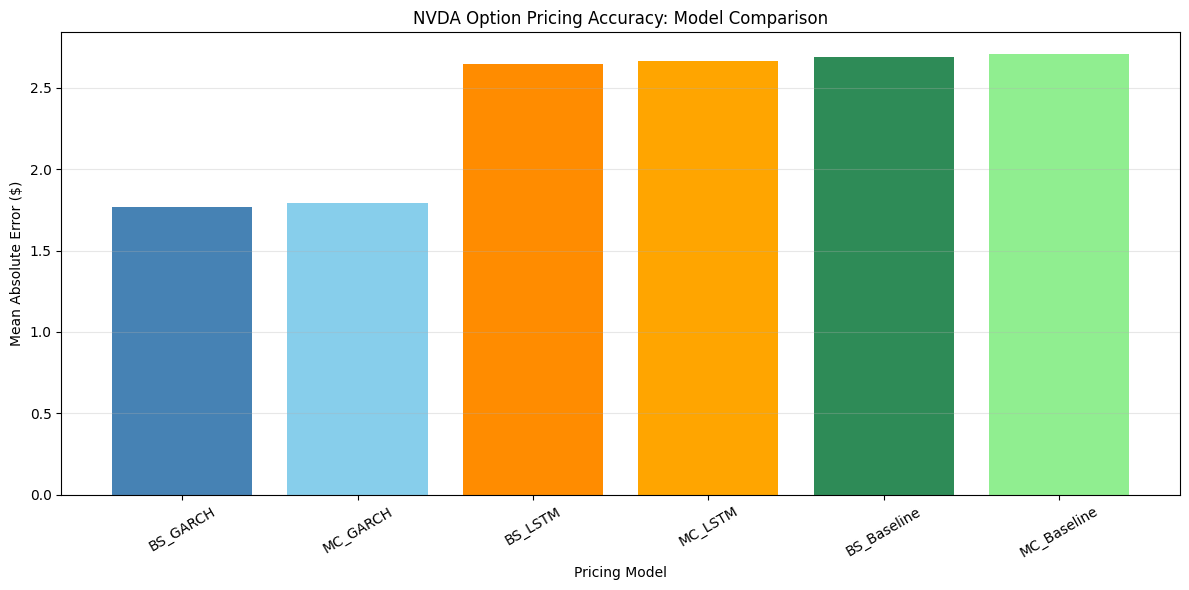

In [38]:
# --------------------------------------------------
# MAE COMPARISON CHART
# --------------------------------------------------

plt.figure(figsize=(12, 6))

plt.bar(
    mae_table["Model"],
    mae_table["MAE"],
    color=[
        "steelblue",
        "skyblue",
        "darkorange",
        "orange",
        "seagreen",
        "lightgreen"
    ][:len(mae_table)]
)

plt.title(
    "NVDA Option Pricing Accuracy: Model Comparison"
)

plt.xlabel("Pricing Model")

plt.ylabel("Mean Absolute Error ($)")

plt.xticks(rotation=30)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

/var/folders/41/z1v1y3vd3hj0dn1s8t7dpssh0000gn/T/ipykernel_12700/2258914874.py:38: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/Users/irikadesai/Desktop/Python Folder/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


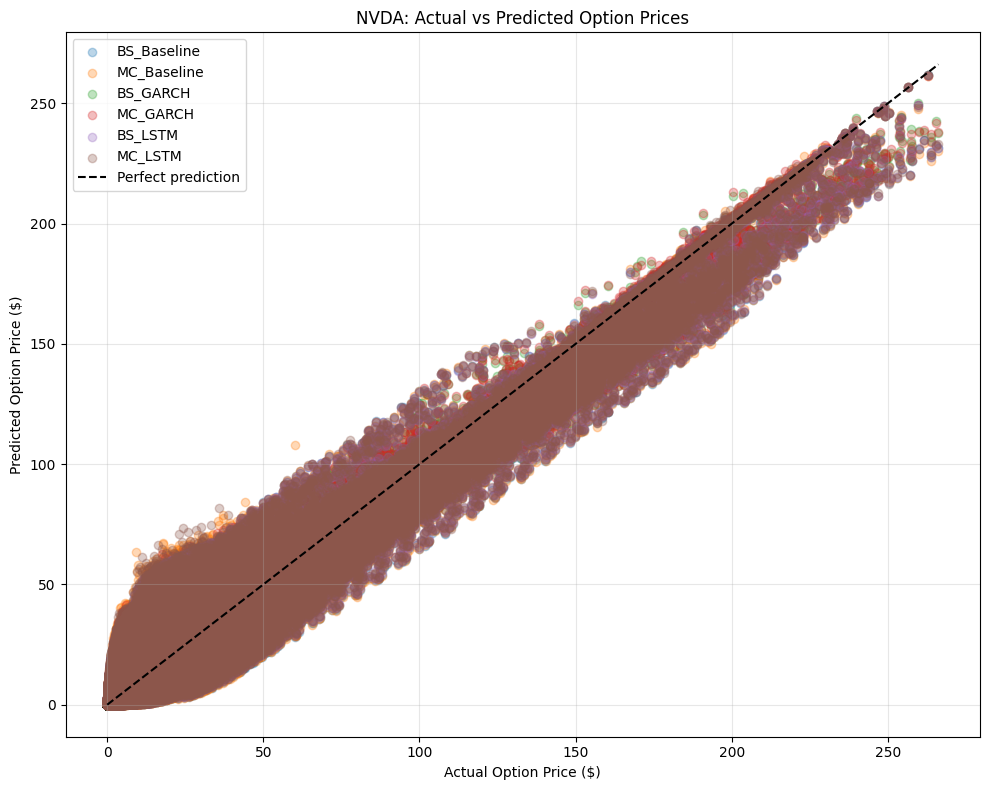

In [39]:
# --------------------------------------------------
# ACTUAL VS PREDICTED PRICES
# --------------------------------------------------

plt.figure(figsize=(10, 8))

for model in model_columns:

    plt.scatter(
        options["market_price"],
        options[model],
        alpha=0.3,
        label=model
    )

maximum_price = max(
    options["market_price"].max(),
    options[model_columns].max().max()
)

plt.plot(
    [0, maximum_price],
    [0, maximum_price],
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Actual Option Price ($)")

plt.ylabel("Predicted Option Price ($)")

plt.title("NVDA: Actual vs Predicted Option Prices")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [40]:
# --------------------------------------------------
# MONTE CARLO VS BLACK-SCHOLES
# --------------------------------------------------

print("\nMONTE CARLO VALIDATION")
print("----------------------")

for bs_model, mc_model in [
    ("BS_Baseline", "MC_Baseline"),
    ("BS_GARCH", "MC_GARCH"),
    ("BS_LSTM", "MC_LSTM")
]:

    difference = np.mean(
        np.abs(
            options[bs_model] - options[mc_model]
        )
    )

    print(
        f"{bs_model} vs {mc_model}: "
        f"Average absolute difference = ${difference:.6f}"
    )


MONTE CARLO VALIDATION
----------------------
BS_Baseline vs MC_Baseline: Average absolute difference = $0.199938
BS_GARCH vs MC_GARCH: Average absolute difference = $0.214560
BS_LSTM vs MC_LSTM: Average absolute difference = $0.201279
